# DemandSense Phase 2: Item-Level Seasonal Demand Forecasting
**Goal:** forecast daily demand (kg) for 12 specific items (4 flowers, 4 vegetables, 4 fruits) that depend on weddings and festivals, and show how the error (MAE) falls as the model improves.

**Items:** Flowers: Rose, Marigold, Jasmine, Lotus | Vegetables: Onion, Potato, Tomato, Paneer_Veg_Mix | Fruits: Banana, Apple, Mango, Pomegranate

**Data note:** the data is synthetic (generated below from documented rules for weddings, festivals, weekends and a small yearly trend). It demonstrates the pipeline; real mandi data would be noisier.

**How to run:** upload `demand_dataset_v2_items.csv` to the Colab Files panel (left sidebar), then Runtime > Run all. If the file is not there, the notebook generates the same dataset itself. Takes about 2 to 3 minutes.

In [ ]:
%pip install -q prophet xgboost
# Colab already has pandas, numpy, matplotlib, seaborn and scikit-learn

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import LabelEncoder

sns.set_style("whitegrid")
TARGET = "demand_units_kg"
TEST_DAYS = 90

Importing plotly failed. Interactive plots will not work.


## 1. Create the dataset
Each item has its own base demand, wedding boost and festival boost. For example Rose and Jasmine jump in wedding season, Marigold jumps around festivals, and Mango sells almost only in April to June.

In [2]:
import os
CSV = "demand_dataset_v2_items.csv"

if os.path.exists(CSV):
    print("Found", CSV, "- using your uploaded dataset (no need to generate one).")
else:
    print("No", CSV, "found - generating the dataset now.")
    import pandas as pd
    import numpy as np
    from datetime import datetime

    np.random.seed(42)  # fixed seed so everyone gets identical data

    START_DATE = datetime(2022, 1, 1)
    END_DATE = datetime(2024, 12, 31)
    dates = pd.date_range(START_DATE, END_DATE, freq="D")

    wedding_months = {11, 12, 1, 2, 4, 5, 6}

    festival_dates = pd.to_datetime([
        "2022-10-24", "2023-11-12", "2024-11-01",   # Diwali
        "2022-10-01", "2023-10-20", "2024-10-09",   # Durga Puja / Navratri
        "2022-08-31", "2023-09-19", "2024-09-07",   # Ganesh Chaturthi
        "2022-03-18", "2023-03-08", "2024-03-25",   # Holi
        "2022-05-02", "2023-04-21", "2024-04-10",   # Eid
    ])

    def festival_weight(date, window=4):
        diffs = np.abs((festival_dates - date).days)
        m = diffs.min()
        return 0.0 if m > window else max(0, 1 - (m / window))

    # ---- Item-level configuration ----
    # base = avg daily demand (kg), wedding_boost/festival_boost = multipliers,
    # season_only = restrict demand to specific months (None = year-round)
    items = {
        "Flowers": {
            "Rose":      {"base": 45, "noise": 6,  "wedding_boost": 3.2, "festival_boost": 1.6, "season_only": None},
            "Marigold":  {"base": 40, "noise": 6,  "wedding_boost": 1.8, "festival_boost": 3.6, "season_only": None},
            "Jasmine":   {"base": 25, "noise": 4,  "wedding_boost": 3.0, "festival_boost": 1.8, "season_only": None},
            "Lotus":     {"base": 10, "noise": 2,  "wedding_boost": 1.3, "festival_boost": 2.4, "season_only": None},
        },
        "Vegetables": {
            "Onion":     {"base": 120, "noise": 14, "wedding_boost": 2.0, "festival_boost": 1.3, "season_only": None},
            "Potato":    {"base": 110, "noise": 13, "wedding_boost": 1.9, "festival_boost": 1.3, "season_only": None},
            "Tomato":    {"base": 90,  "noise": 12, "wedding_boost": 1.8, "festival_boost": 1.4, "season_only": None},
            "Paneer_Veg_Mix": {"base": 60, "noise": 9, "wedding_boost": 2.6, "festival_boost": 1.2, "season_only": None},
        },
        "Fruits": {
            "Banana":      {"base": 55, "noise": 7, "wedding_boost": 1.5, "festival_boost": 2.2, "season_only": None},
            "Apple":       {"base": 40, "noise": 6, "wedding_boost": 1.8, "festival_boost": 1.6, "season_only": None},
            "Mango":       {"base": 50, "noise": 8, "wedding_boost": 1.4, "festival_boost": 1.2, "season_only": {4, 5, 6}},
            "Pomegranate": {"base": 30, "noise": 5, "wedding_boost": 1.5, "festival_boost": 2.0, "season_only": None},
        },
    }

    rows = []
    for category, item_dict in items.items():
        for item_name, cfg in item_dict.items():
            for d in dates:
                if cfg["season_only"] and d.month not in cfg["season_only"]:
                    demand = max(0, np.random.normal(cfg["base"] * 0.05, cfg["noise"] * 0.3))
                    rows.append({
                        "date": d.strftime("%Y-%m-%d"), "category": category, "item": item_name,
                        "demand_units_kg": round(demand, 1),
                        "is_wedding_season": int(d.month in wedding_months),
                        "festival_proximity_score": round(festival_weight(d), 2),
                        "day_of_week": d.strftime("%A"), "month": d.month, "year": d.year,
                    })
                    continue

                base = cfg["base"]
                wedding_mult = cfg["wedding_boost"] if d.month in wedding_months else 1.0
                if d.month in wedding_months and d.weekday() in (5, 6):
                    wedding_mult *= 1.15
                fw = festival_weight(d)
                festival_mult = 1 + fw * (cfg["festival_boost"] - 1)
                weekly_mult = 1.1 if d.weekday() == 6 else 1.0
                trend_mult = 1 + 0.04 * (d.year - START_DATE.year)
                noise = np.random.normal(0, cfg["noise"])
                demand = max(0, round(base * wedding_mult * festival_mult * weekly_mult * trend_mult + noise, 1))

                rows.append({
                    "date": d.strftime("%Y-%m-%d"), "category": category, "item": item_name,
                    "demand_units_kg": demand,
                    "is_wedding_season": int(d.month in wedding_months),
                    "festival_proximity_score": round(fw, 2),
                    "day_of_week": d.strftime("%A"), "month": d.month, "year": d.year,
                })

    df = pd.DataFrame(rows)
    df.to_csv("demand_dataset_v2_items.csv", index=False)
    print("Dataset created:", df.shape)

Found demand_dataset_v2_items.csv - using your uploaded dataset (no need to generate one).


## 2. Look at the data
Each line is one item's average demand by month. Different items peak in different months, which is why Phase 2 models items, not just categories.

category
Flowers              [Rose, Marigold, Jasmine, Lotus]
Fruits            [Banana, Apple, Mango, Pomegranate]
Vegetables    [Onion, Potato, Tomato, Paneer_Veg_Mix]


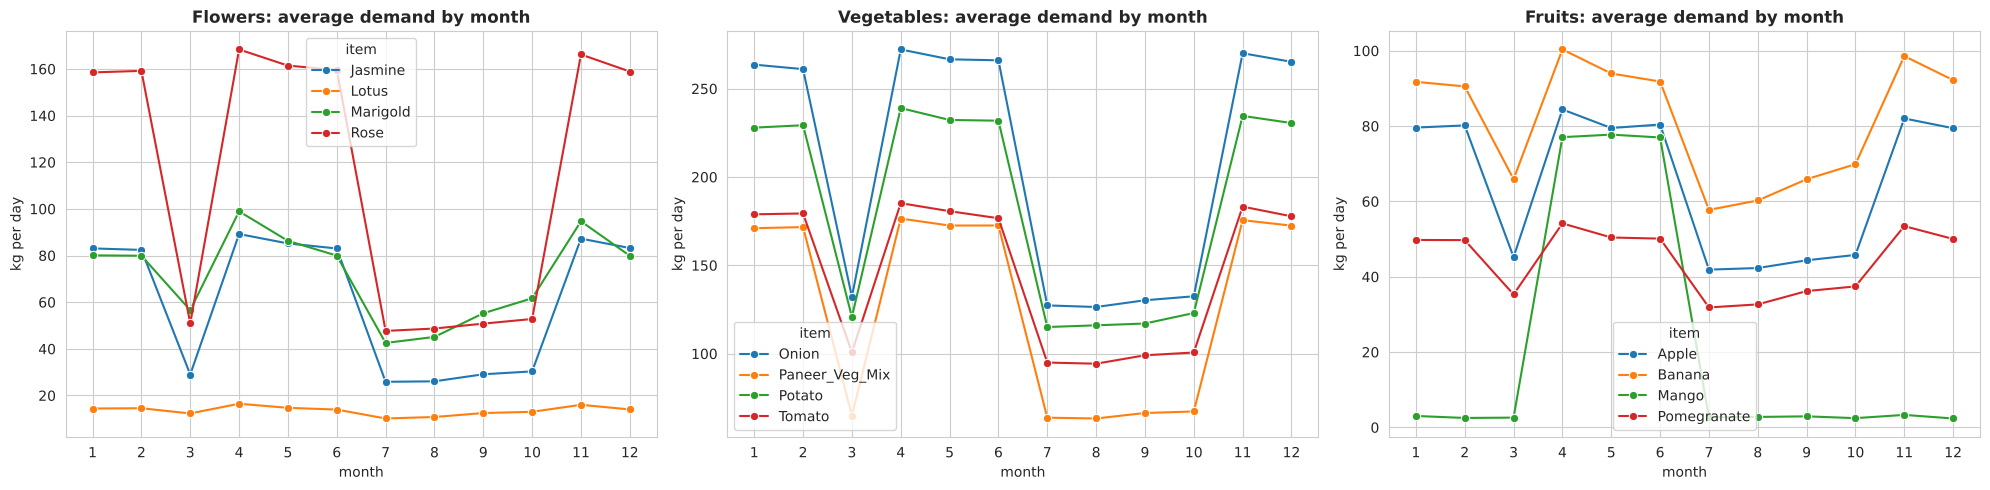

In [3]:
df = pd.read_csv("demand_dataset_v2_items.csv", parse_dates=["date"])
print(df.groupby("category")["item"].unique().to_string())

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, cat in zip(axes, ["Flowers", "Vegetables", "Fruits"]):
    m = df[df.category == cat].groupby(["item", "month"])[TARGET].mean().reset_index()
    sns.lineplot(data=m, x="month", y=TARGET, hue="item", marker="o", ax=ax)
    ax.set_title(f"{cat}: average demand by month", fontweight="bold")
    ax.set_xticks(range(1, 13)); ax.set_ylabel("kg per day")
plt.tight_layout(); plt.show()

## 3. Feature engineering
Features are the clues the model gets:
- `is_wedding_season`, `festival_proximity_score` (0 to 1, highest on the festival day, falls to 0 four days away)
- `doy_sin`, `doy_cos`: day of year as a circle, so 31 Dec and 1 Jan are neighbours
- `dow_num`: day of week, `item_encoded`: which item
- `lag_1`, `lag_7`: yesterday's and last week's demand (used only in the last model, which is a next-day forecast)

In [4]:
df = df.sort_values(["item", "date"]).reset_index(drop=True)
df["day_of_year"] = df["date"].dt.dayofyear
df["doy_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365)
df["doy_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365)
df["dow_num"] = df["date"].dt.dayofweek
df["item_encoded"] = LabelEncoder().fit_transform(df["item"])

g = df.groupby("item")[TARGET]
df["lag_1"] = g.shift(1)
df["lag_7"] = g.shift(7)
df["last_year"] = g.shift(364)     # same day last year, used by a baseline

BASE_FEATURES = ["is_wedding_season", "festival_proximity_score", "doy_sin", "doy_cos", "dow_num", "item_encoded"]
LAG_FEATURES = BASE_FEATURES + ["lag_1", "lag_7"]

split_date = df["date"].max() - pd.Timedelta(days=TEST_DAYS)
train = df[df["date"] <= split_date].copy()
test = df[df["date"] > split_date].copy()
print(f"Train: {len(train)} rows, {train.date.min().date()} to {train.date.max().date()}")
print(f"Test : {len(test)} rows, {test.date.min().date()} to {test.date.max().date()}  (last {TEST_DAYS} days, never seen in training)")

Train: 12072 rows, 2022-01-01 to 2024-10-02
Test : 1080 rows, 2024-10-03 to 2024-12-31  (last 90 days, never seen in training)


## 4. How we measure
**MAE** = average gap between prediction and reality in kg (lower is better). **MAPE** = the same gap as a percentage; days with demand of 1 kg or less are skipped so near-zero days do not blow it up.

Every model below is tested on the **same last 90 days**.

In [5]:
results = []   # (model name, MAE, MAPE, horizon note)
test_preds = {}

def score(name, pred, note="90 days ahead"):
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    actual = test[TARGET].values
    mae = mean_absolute_error(actual, pred)
    mask = actual > 1
    mape = (np.abs(actual[mask] - pred[mask]) / actual[mask]).mean() * 100
    results.append({"Model": name, "MAE (kg)": round(mae, 2), "MAPE (%)": round(mape, 2), "Forecast type": note})
    test_preds[name] = pred
    print(f"{name:45s} MAE {mae:6.2f} kg | MAPE {mape:6.2f}%")

## 5. The improvement ladder
### Step 1: Naive average
Predict each item's average training demand every day. No seasonality at all.

In [6]:
item_mean = train.groupby("item")[TARGET].mean()
score("1. Naive: item average", test["item"].map(item_mean))

1. Naive: item average                        MAE  34.06 kg | MAPE  74.45%


### Step 2: Same day last year
Predict the value from 364 days earlier. It knows about seasons, but festival dates move each year, so it misses them.

In [7]:
score("2. Same day last year", test["last_year"].fillna(test["item"].map(item_mean)))

2. Same day last year                         MAE  15.97 kg | MAPE  23.42%


### Step 3: Prophet with dates only
Prophet learns yearly and weekly patterns for each item separately, but it does not know about weddings or festivals.

In [8]:
def run_prophet(use_regressors):
    regs = ["is_wedding_season", "festival_proximity_score"] if use_regressors else []
    out = pd.Series(index=test.index, dtype=float)
    for item, tr in train.groupby("item"):
        te = test[test["item"] == item]
        m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False, changepoint_prior_scale=0.1)
        for r in regs:
            m.add_regressor(r)
        m.fit(tr.rename(columns={"date": "ds", TARGET: "y"})[["ds", "y"] + regs])
        out.loc[te.index] = m.predict(te.rename(columns={"date": "ds"})[["ds"] + regs])["yhat"].values
    return out.values

pred_prophet = run_prophet(False)
score("3. Prophet (dates only)", pred_prophet)

05:11:55 - cmdstanpy - INFO - Chain [1] start processing


05:11:55 - cmdstanpy - INFO - Chain [1] done processing


05:11:55 - cmdstanpy - INFO - Chain [1] start processing


05:11:55 - cmdstanpy - INFO - Chain [1] done processing


05:11:55 - cmdstanpy - INFO - Chain [1] start processing


05:11:55 - cmdstanpy - INFO - Chain [1] done processing


... (15 outputs left out)

05:11:57 - cmdstanpy - INFO - Chain [1] done processing


05:11:57 - cmdstanpy - INFO - Chain [1] start processing


05:11:57 - cmdstanpy - INFO - Chain [1] done processing


3. Prophet (dates only)                       MAE  13.51 kg | MAPE  20.71%


### Step 4: Prophet + wedding and festival regressors
We tell Prophet about the wedding flag and the festival score using `add_regressor`. This is the biggest single improvement.

In [9]:
pred_prophet_reg = run_prophet(True)
score("4. Prophet + wedding & festival regressors", pred_prophet_reg)

05:11:57 - cmdstanpy - INFO - Chain [1] start processing


05:11:57 - cmdstanpy - INFO - Chain [1] done processing


05:11:58 - cmdstanpy - INFO - Chain [1] start processing


05:11:58 - cmdstanpy - INFO - Chain [1] done processing


05:11:58 - cmdstanpy - INFO - Chain [1] start processing


05:11:58 - cmdstanpy - INFO - Chain [1] done processing


... (15 outputs left out)

05:12:00 - cmdstanpy - INFO - Chain [1] done processing


05:12:00 - cmdstanpy - INFO - Chain [1] start processing


05:12:00 - cmdstanpy - INFO - Chain [1] done processing


4. Prophet + wedding & festival regressors    MAE   8.43 kg | MAPE  15.36%


### Step 5: XGBoost, one model for all items
XGBoost reads the whole feature table, including which item it is, so it can learn that a festival lifts Marigold far more than Onion.

In [10]:
xgb_base = xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_base.fit(train[BASE_FEATURES], train[TARGET])
score("5. XGBoost (default settings)", xgb_base.predict(test[BASE_FEATURES]))

5. XGBoost (default settings)                 MAE   8.13 kg | MAPE  15.11%


### Step 6: XGBoost with tuned settings
We search a small grid of settings. The search uses `TimeSeriesSplit` inside the training data only, so the test set stays untouched. Tuning does not always lower MAE; if the default settings were already good, the gain is tiny, and that is a normal, honest result.

In [11]:
train_sorted = train.sort_values("date")
grid = {"n_estimators": [200, 400], "max_depth": [3, 5, 7], "learning_rate": [0.03, 0.1]}
search = GridSearchCV(
    xgb.XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=42),
    grid, cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_absolute_error", n_jobs=-1)
search.fit(train_sorted[BASE_FEATURES], train_sorted[TARGET])
print("Best settings:", search.best_params_)
xgb_tuned = search.best_estimator_
score("6. XGBoost (tuned with TimeSeriesSplit)", xgb_tuned.predict(test[BASE_FEATURES]))

Best settings: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}
6. XGBoost (tuned with TimeSeriesSplit)       MAE   8.15 kg | MAPE  14.56%


### Step 7: XGBoost + lag features (next-day forecast)
Adding yesterday's and last week's real demand helps a lot, **but** it means we can only forecast one day ahead (tomorrow), because we need today's real value. It is a different, easier task, so it is shown separately and not counted as a 90-day forecast.

In [12]:
xgb_lag = xgb.XGBRegressor(**search.best_params_, subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_lag.fit(train[LAG_FEATURES], train[TARGET])
score("7. XGBoost + lags (next-day only)", xgb_lag.predict(test[LAG_FEATURES]), note="1 day ahead")

7. XGBoost + lags (next-day only)             MAE   8.08 kg | MAPE  11.59%


## 6. Results: how MAE improves
Because we generated the data, we know how much random noise we added. No model can beat that noise, so it gives an approximate **best possible MAE** to compare against.

In [13]:
# Approximate best possible MAE: the average size of the random noise we added in the generator
NOISE_SD = {"Rose": 6, "Marigold": 6, "Jasmine": 4, "Lotus": 2, "Onion": 14, "Potato": 13, "Tomato": 12,
            "Paneer_Veg_Mix": 9, "Banana": 7, "Apple": 6, "Mango": 8, "Pomegranate": 5}   # from the generator
floor = []
for _, r in test.iterrows():
    off_season_mango = r["item"] == "Mango" and r["month"] not in (4, 5, 6)
    sd = NOISE_SD[r["item"]] * (0.3 if off_season_mango else 1.0)
    floor.append(0.798 * sd)       # mean absolute value of a normal variable = 0.798 x its std
NOISE_FLOOR = round(float(np.mean(floor)), 2)
print(f"Approximate best possible MAE (pure noise): {NOISE_FLOOR} kg")

Approximate best possible MAE (pure noise): 5.75 kg


,Model,MAE (kg),MAPE (%),Forecast type,MAE improvement vs Step 1
0,1. Naive: item average,34.06,74.45,90 days ahead,0.0%
1,2. Same day last year,15.97,23.42,90 days ahead,53.1%
2,3. Prophet (dates only),13.51,20.71,90 days ahead,60.3%
3,4. Prophet + wedding & festival regressors,8.43,15.36,90 days ahead,75.2%
4,5. XGBoost (default settings),8.13,15.11,90 days ahead,76.1%
5,6. XGBoost (tuned with TimeSeriesSplit),8.15,14.56,90 days ahead,76.1%
6,7. XGBoost + lags (next-day only),8.08,11.59,1 day ahead,76.3%


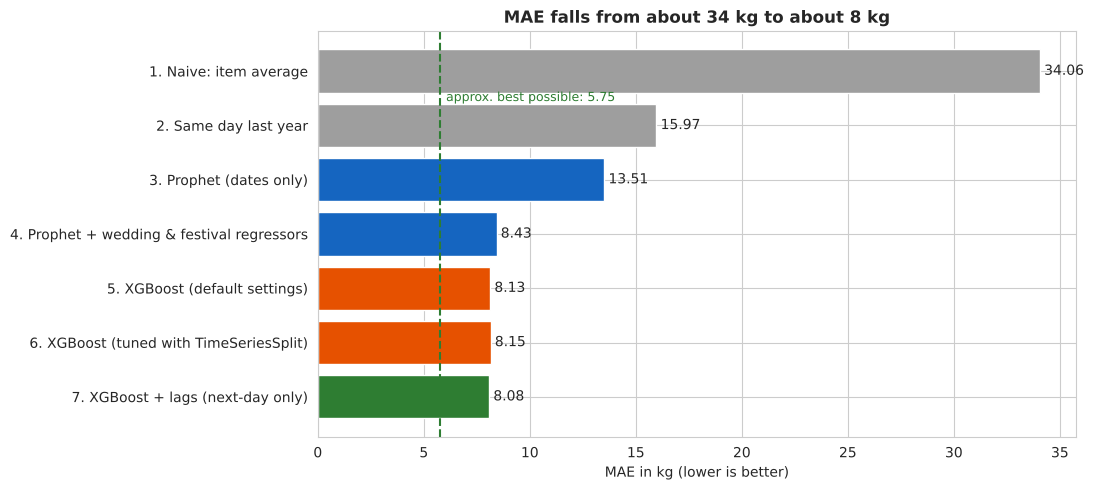

In [14]:
res = pd.DataFrame(results)
base_mae = res.loc[0, "MAE (kg)"]
res["MAE improvement vs Step 1"] = ((1 - res["MAE (kg)"] / base_mae) * 100).round(1).astype(str) + "%"
display(res)
res.to_csv("model_results.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#9e9e9e", "#9e9e9e", "#1565C0", "#1565C0", "#E65100", "#E65100", "#2e7d32"]
bars = ax.barh(res["Model"][::-1], res["MAE (kg)"][::-1], color=colors[::-1])
for b, v in zip(bars, res["MAE (kg)"][::-1]):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center")
ax.axvline(NOISE_FLOOR, color="#2e7d32", linestyle="--")
ax.text(NOISE_FLOOR + 0.3, 5.45, f"approx. best possible: {NOISE_FLOOR}", color="#2e7d32", fontsize=9)
ax.set_xlabel("MAE in kg (lower is better)")
ax.set_title("MAE falls from about 34 kg to about 8 kg", fontweight="bold")
plt.tight_layout(); plt.savefig("mae_improvement.png", dpi=150); plt.show()

## 7. Per-item error (best 90-day model)

In [15]:
best90 = res[res["Forecast type"] == "90 days ahead"].sort_values("MAE (kg)").iloc[0]["Model"]
print("Best model that forecasts 90 days ahead:", best90)
per_item = []
for item, sub in test.groupby("item"):
    idx = test.index.get_indexer(sub.index)
    a = sub[TARGET].values
    naive = mean_absolute_error(a, test_preds["1. Naive: item average"][idx])
    best = mean_absolute_error(a, test_preds[best90][idx])
    per_item.append({"Item": item, "Naive MAE": round(naive, 2), "Best model MAE": round(best, 2),
                     "Improvement": f"{(1 - best / naive) * 100:.0f}%"})
per_item = pd.DataFrame(per_item).sort_values("Best model MAE")
display(per_item)
per_item.to_csv("per_item_results.csv", index=False)

Best model that forecasts 90 days ahead: 5. XGBoost (default settings)


,Item,Naive MAE,Best model MAE,Improvement
3,Lotus,3.30,1.98,40%
4,Mango,20.20,3.46,83%
8,Pomegranate,10.47,4.36,58%
0,Apple,18.16,5.06,72%
2,Jasmine,28.87,5.51,81%
1,Banana,19.10,6.36,67%
5,Marigold,24.32,6.92,72%
10,Rose,56.64,7.90,86%
11,Tomato,42.54,12.15,71%
7,Paneer_Veg_Mix,55.40,12.28,78%


## 8. Actual vs predicted
The orange line (best model) follows the Diwali spike on 1 Nov 2024. The grey line (naive) cannot.

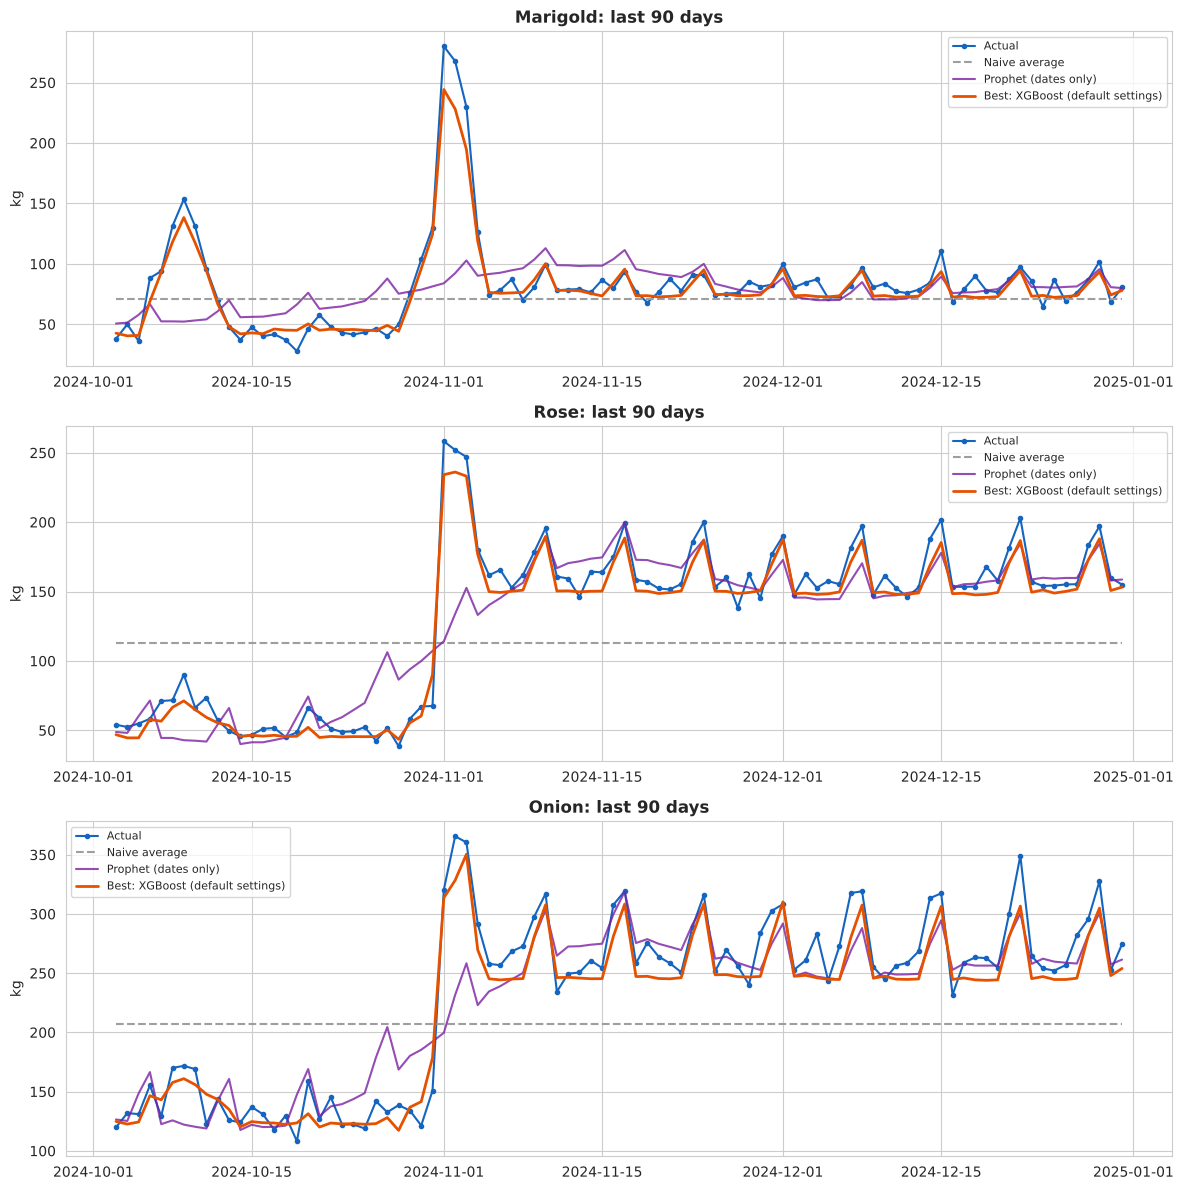

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
for ax, item in zip(axes, ["Marigold", "Rose", "Onion"]):
    sub = test[test["item"] == item]; idx = test.index.get_indexer(sub.index)
    ax.plot(sub["date"], sub[TARGET], label="Actual", color="#1565C0", marker="o", markersize=3)
    ax.plot(sub["date"], test_preds["1. Naive: item average"][idx], label="Naive average", color="#9e9e9e", linestyle="--")
    ax.plot(sub["date"], test_preds["3. Prophet (dates only)"][idx], label="Prophet (dates only)", color="#7b1fa2", alpha=0.8)
    ax.plot(sub["date"], test_preds[best90][idx], label=f"Best: {best90[3:]}", color="#E65100", linewidth=2)
    ax.set_title(f"{item}: last 90 days", fontweight="bold"); ax.set_ylabel("kg"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("actual_vs_predicted.png", dpi=150); plt.show()

## 9. What the model relies on

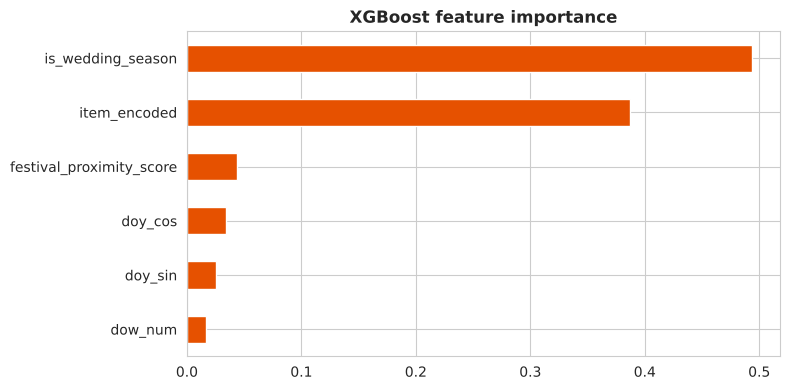

In [17]:
imp = pd.Series(xgb_tuned.feature_importances_, index=BASE_FEATURES).sort_values()
plt.figure(figsize=(8, 4)); imp.plot.barh(color="#E65100")
plt.title("XGBoost feature importance", fontweight="bold"); plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150); plt.show()

## 10. Conclusion

In [18]:
first, last90 = res.iloc[0], res[res["Forecast type"] == "90 days ahead"].sort_values("MAE (kg)").iloc[0]
print(f"MAE fell from {first['MAE (kg)']} kg (naive average) to {last90['MAE (kg)']} kg ({last90['Model']}).")
prophet_plain = res.loc[res.Model.str.startswith('3.'), 'MAE (kg)'].iloc[0]
prophet_reg = res.loc[res.Model.str.startswith('4.'), 'MAE (kg)'].iloc[0]
print(f"Adding wedding and festival regressors to Prophet: {prophet_plain} kg -> {prophet_reg} kg.")
print(f"Approximate best possible MAE on this synthetic data is {NOISE_FLOOR} kg; the best 90-day model is {last90['MAE (kg)'] - NOISE_FLOOR:.1f} kg above it.")
print("Limitations: data is synthetic; lag model is next-day only; test window is one 90-day period.")

MAE fell from 34.06 kg (naive average) to 8.13 kg (5. XGBoost (default settings)).
Adding wedding and festival regressors to Prophet: 13.51 kg -> 8.43 kg.
Approximate best possible MAE on this synthetic data is 5.75 kg; the best 90-day model is 2.4 kg above it.
Limitations: data is synthetic; lag model is next-day only; test window is one 90-day period.


**Future scope:** real Agmarknet / mandi data, more festivals and weather, forecast intervals, a wastage-risk and procurement module, and a Streamlit dashboard connected to the saved model.